In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform
from sklearn.decomposition import PCA

In [2]:
expression_path = "data/brca_metabric/data_mrna_illumina_microarray.txt"

# Load expression data
expression_df = pd.read_csv(
    expression_path,
    sep="\t",
    low_memory=False
)

print("Original shape:", expression_df.shape)

# Check duplicates before filtering
print("Total genes (rows):", expression_df.shape[0])

print("Duplicate Hugo Symbols:",
      expression_df["Hugo_Symbol"].duplicated().sum())

print("Duplicate Entrez Gene IDs:",
      expression_df["Entrez_Gene_Id"].dropna().duplicated().sum())

print("Unique Hugo Symbols:",
      expression_df["Hugo_Symbol"].nunique())

print("Unique Entrez Gene IDs:",
      expression_df["Entrez_Gene_Id"].nunique())

print("Missing Entrez IDs:",
      expression_df["Entrez_Gene_Id"].isna().sum())


# Find all rows with duplicate Entrez IDs
duplicates = expression_df[
    expression_df.duplicated("Entrez_Gene_Id", keep=False)
].copy()

print("\nRows involved in duplicates:", len(duplicates))

print("Distinct duplicated Entrez IDs:",
      duplicates["Entrez_Gene_Id"].nunique())


# Check whether duplicated Entrez IDs share the same Hugo Symbol
symbol_counts = (
    duplicates.groupby("Entrez_Gene_Id")["Hugo_Symbol"]
    .nunique()
)

print("Duplicated Entrez IDs with one Hugo Symbol:",
      (symbol_counts == 1).sum())

print("Duplicated Entrez IDs with multiple Hugo Symbols:",
      (symbol_counts > 1).sum())


# Identify Entrez IDs with multiple Hugo Symbols
conflicting_ids = symbol_counts[symbol_counts > 1].index

conflicting_genes = duplicates[
    duplicates["Entrez_Gene_Id"].isin(conflicting_ids)
]

print("\nExamples of Entrez IDs with multiple Hugo Symbols:")

print(
    conflicting_genes[
        ["Hugo_Symbol", "Entrez_Gene_Id"]
    ].sort_values("Entrez_Gene_Id").head(30)
)


# Check whether duplicated Entrez IDs have different expression profiles
gene_cols = ["Hugo_Symbol", "Entrez_Gene_Id"]
sample_cols = expression_df.columns.difference(gene_cols).tolist()

unique_profiles = duplicates.drop_duplicates(
    subset=["Entrez_Gene_Id"] + sample_cols
)

profile_counts = unique_profiles.groupby("Entrez_Gene_Id").size()

print("\nEntrez IDs with different expression profiles:",
      (profile_counts > 1).sum())

print("Entrez IDs with identical expression profiles:",
      (profile_counts == 1).sum())


# Remove genes with missing Entrez IDs
expression_df = expression_df.dropna(subset=["Entrez_Gene_Id"]).copy()

# Convert Entrez IDs to numeric
expression_df["Entrez_Gene_Id"] = pd.to_numeric(
    expression_df["Entrez_Gene_Id"],
    errors="coerce"
)

expression_df = expression_df.dropna(subset=["Entrez_Gene_Id"])
expression_df["Entrez_Gene_Id"] = expression_df["Entrez_Gene_Id"].astype(int)

# Remove Hugo Symbol column
expression_df = expression_df.drop(columns=["Hugo_Symbol"])

# Convert expression values to numeric
expression_df = expression_df.set_index("Entrez_Gene_Id")
expression_df = expression_df.apply(pd.to_numeric, errors="coerce")

# Handle duplicate Entrez IDs by averaging expression values
expression_df = expression_df.groupby(level=0).mean()

# Transpose: patients become rows, genes become columns
expression_df = expression_df.T

print("\nExpression matrix:", expression_df.shape)
print("Duplicate Entrez IDs:", expression_df.columns.duplicated().sum())

# Check missing expression values
print("Total missing values:", expression_df.isna().sum().sum())
print("Genes with missing values:", expression_df.isna().any(axis=0).sum())
print("Patients with missing values:", expression_df.isna().any(axis=1).sum())

Original shape: (20603, 1982)
Total genes (rows): 20603
Duplicate Hugo Symbols: 218
Duplicate Entrez Gene IDs: 411
Unique Hugo Symbols: 20385
Unique Entrez Gene IDs: 20192
Missing Entrez IDs: 0

Rows involved in duplicates: 791
Distinct duplicated Entrez IDs: 380
Duplicated Entrez IDs with one Hugo Symbol: 189
Duplicated Entrez IDs with multiple Hugo Symbols: 191

Examples of Entrez IDs with multiple Hugo Symbols:
       Hugo_Symbol  Entrez_Gene_Id
11082        ZFHX3             463
17012     C16orf47             463
12473       ATP5ME             521
5650         ATP5I             521
8191           DST             667
17961        BPAG1             667
20327        SEPT7             989
1176       SEPTIN7             989
15110        S1PR3            1903
18041      C9orf47            1903
5971         KMT2A            4297
2313           MLL            4297
19229        MLLT4            4301
12089         AFDN            4301
5430         NELL1            4745
584         IDH3GL    

In [3]:
clinical_path = "data/brca_metabric/data_clinical_patient.txt"

# Load clinical patient data
clinical_df = pd.read_csv(
    clinical_path,
    sep="\t",
    comment="#",
    low_memory=False
)

print("Clinical data shape:", clinical_df.shape)
print("Columns:", clinical_df.columns.tolist())

# Check PAM50 + Claudin-low subtype distribution
print(clinical_df["CLAUDIN_SUBTYPE"].value_counts(dropna=False))

Clinical data shape: (2509, 24)
Columns: ['PATIENT_ID', 'LYMPH_NODES_EXAMINED_POSITIVE', 'NPI', 'CELLULARITY', 'CHEMOTHERAPY', 'COHORT', 'ER_IHC', 'HER2_SNP6', 'HORMONE_THERAPY', 'INFERRED_MENOPAUSAL_STATE', 'SEX', 'INTCLUST', 'AGE_AT_DIAGNOSIS', 'OS_MONTHS', 'OS_STATUS', 'CLAUDIN_SUBTYPE', 'THREEGENE', 'VITAL_STATUS', 'LATERALITY', 'RADIO_THERAPY', 'HISTOLOGICAL_SUBTYPE', 'BREAST_SURGERY', 'RFS_MONTHS', 'RFS_STATUS']
CLAUDIN_SUBTYPE
LumA           700
NaN            529
LumB           475
Her2           224
claudin-low    218
Basal          209
Normal         148
NC               6
Name: count, dtype: int64


In [4]:
# 2000 genes

# Exclude genes with >10% missing values
missing_fraction = expression_df.isna().mean()

expression_filtered = expression_df.loc[
    :, missing_fraction <= 0.10
]

print("Genes removed (>10% missing):",
      (missing_fraction > 0.10).sum())

print("Genes remaining:", expression_filtered.shape[1])

# Calculate gene-specific medians
gene_medians = expression_filtered.median(axis=0)

# Calculate median absolute deviation (MAD)
gene_mad = (
    expression_filtered
    .sub(gene_medians, axis=1)
    .abs()
    .median(axis=0)
)

# Remove genes with no variability
gene_mad = gene_mad[gene_mad > 0]

print("Genes with nonzero MAD:", len(gene_mad))

# Select the top 2,000 genes
top_2000_genes = gene_mad.nlargest(2000).index

X_2000 = expression_filtered[top_2000_genes].copy()

print("Selected expression matrix:", X_2000.shape)

print("Top 10 genes by MAD:")
print(gene_mad.nlargest(10))

# Check missing values in selected genes
print("Total missing values:", X_2000.isna().sum().sum())

print("Genes with missing values:",
      X_2000.isna().any(axis=0).sum())

print("Patients with missing values:",
      X_2000.isna().any(axis=1).sum())

# Check how many genes have multiple Hugo Symbol mappings
ambiguous_top_2000 = top_2000_genes.intersection(conflicting_ids)

print("Genes with multiple Hugo Symbols in top 2000:",
      len(ambiguous_top_2000))

print("Ambiguous Entrez ID:", ambiguous_top_2000.tolist())

print(
    conflicting_genes[
        conflicting_genes["Entrez_Gene_Id"].isin(ambiguous_top_2000)
    ][["Hugo_Symbol", "Entrez_Gene_Id"]]
)

Genes removed (>10% missing): 0
Genes remaining: 20192
Genes with nonzero MAD: 20192
Selected expression matrix: (1980, 2000)
Top 10 genes by MAD:
Entrez_Gene_Id
4250      2.654036
7031      2.434716
5304      2.401594
10647     2.316080
118430    2.254858
10451     2.147834
4680      1.964515
6286      1.948658
9         1.792440
149563    1.789644
dtype: float64
Total missing values: 6
Genes with missing values: 4
Patients with missing values: 6
Genes with multiple Hugo Symbols in top 2000: 1
Ambiguous Entrez ID: [221960]
     Hugo_Symbol  Entrez_Gene_Id
242        CCZ1B          221960
8558    C7orf28B          221960


In [5]:
#Imputing missing values using gene-specific medians
imputer = SimpleImputer(strategy="median")

X_2000_imputed = pd.DataFrame(
    imputer.fit_transform(X_2000),
    index=X_2000.index,
    columns=X_2000.columns
)

print("Imputed expression matrix:", X_2000_imputed.shape)
print("Missing values:", X_2000_imputed.isna().sum().sum())

Imputed expression matrix: (1980, 2000)
Missing values: 0


In [6]:
#Checking missingness
# Total missing values
print("Total missing:", X_2000.isna().sum().sum())

# Genes with missing values
print("Genes affected:", X_2000.isna().any().sum())

# Patients with missing values
print("Patients affected:", X_2000.isna().any(axis=1).sum())

# Percentage of missing values
print("Percent missing:",
      X_2000.isna().mean().mean() * 100)

Total missing: 6
Genes affected: 4
Patients affected: 6
Percent missing: 0.00015151515151515152


In [7]:
# Load sample-level clinical data
sample_path = "data/brca_metabric/data_clinical_sample.txt"

sample_df = pd.read_csv(
    sample_path,
    sep="\t",
    comment="#",
    low_memory=False
)

# Match patient IDs with subtype labels
sample_subtypes = sample_df[
    ["SAMPLE_ID", "PATIENT_ID"]
].merge(
    clinical_df[["PATIENT_ID", "CLAUDIN_SUBTYPE"]],
    on="PATIENT_ID",
    how="left"
)

# Align labels to expression samples
sample_subtypes = sample_subtypes.set_index("SAMPLE_ID")

pam50_labels = sample_subtypes["CLAUDIN_SUBTYPE"].reindex(
    X_2000_imputed.index
)

print("Expression samples:", len(X_2000_imputed))
print("Samples with subtype labels:", pam50_labels.notna().sum())
print("Samples without subtype labels:", pam50_labels.isna().sum())

print("\nSubtype distribution:")
print(pam50_labels.value_counts(dropna=False))

# Check that every patient has a subtype label
print("Patients in expression matrix:", X_2000_imputed.shape[0])
print("Patients with subtype labels:", pam50_labels.notna().sum())

# Check that patient IDs match
print("Patient IDs match:",
      X_2000_imputed.index.equals(pam50_labels.index))

# Check for missing subtype labels
print("Missing subtype labels:",
      pam50_labels.isna().sum())

# Check selected genes
print("Selected genes:", X_2000_imputed.shape[1])

Expression samples: 1980
Samples with subtype labels: 1980
Samples without subtype labels: 0

Subtype distribution:
CLAUDIN_SUBTYPE
LumA           700
LumB           475
Her2           224
claudin-low    218
Basal          209
Normal         148
NC               6
Name: count, dtype: int64
Patients in expression matrix: 1980
Patients with subtype labels: 1980
Patient IDs match: True
Missing subtype labels: 0
Selected genes: 2000


In [8]:
# Check the data before clustering
# Check for duplicate IDs before matching
assert not sample_df["SAMPLE_ID"].duplicated().any()
assert not clinical_df["PATIENT_ID"].duplicated().any()
assert X_2000_imputed.shape[0] >= 5, "Too few patients."
assert X_2000_imputed.shape[1] == 2000, "Expected 2000 genes."
assert X_2000_imputed.notna().all().all(), "Missing expression values found."

# Standardize gene expression values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_2000_imputed)

print("Scaled expression matrix:", X_scaled.shape)
print("Missing values after scaling:", np.isnan(X_scaled).sum())

Scaled expression matrix: (1980, 2000)
Missing values after scaling: 0


In [9]:
# Perform PCA using the same settings as k-means from Sydney's code
from sklearn.decomposition import PCA

# Perform PCA and retain the first 20 PCs
pca = PCA(n_components=20, svd_solver="full")
X_pca = pca.fit_transform(X_scaled)

print("Original matrix shape:", X_scaled.shape)
print("PCA matrix shape:", X_pca.shape)

print(
    "Variance explained by 20 PCs:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

print("NaN values:", np.isnan(X_pca).sum())
print("Infinite values:", np.isinf(X_pca).sum())

Original matrix shape: (1980, 2000)
PCA matrix shape: (1980, 20)
Variance explained by 20 PCs: 58.41%
NaN values: 0
Infinite values: 0


In [10]:
# Hierarchical clustering using the first 20 PCs

Z = linkage(
    X_pca,
    method="ward",
    metric="euclidean"
)

ward_clusters = fcluster(
    Z,
    t=5,
    criterion="maxclust"
)

print("Number of clusters:",
      len(np.unique(ward_clusters)))

print("Patients per cluster:")
print(pd.Series(ward_clusters).value_counts().sort_index())

Number of clusters: 5
Patients per cluster:
1    205
2    363
3    694
4    174
5    544
Name: count, dtype: int64


 k  silhouette        wcss
 2       0.166 1973935.822
 3       0.108 1777686.635
 4       0.105 1671723.910
 5       0.105 1571695.231
 6       0.108 1507176.898
 7       0.096 1454770.138
 8       0.079 1412921.299
 9       0.075 1375227.992
10       0.079 1338434.271


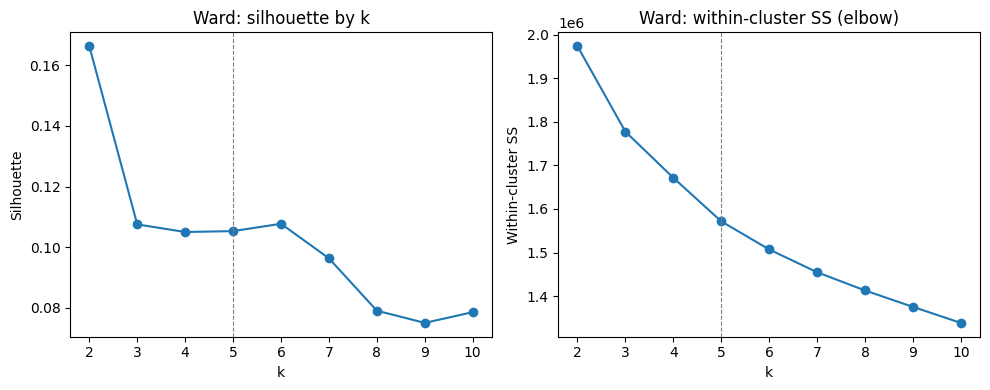

In [11]:
def wcss(X, labels):
    """Total within-cluster sum of squares (elbow plot)."""
    total = 0.0
    for c in np.unique(labels):
        pts = X[labels == c]
        total += ((pts - pts.mean(axis=0)) ** 2).sum()
    return total

# Compute pairwise distances once with scipy (avoids the sklearn/BLAS matmul
# warnings seen on some Mac setups) and reuse them for every k.
D = squareform(pdist(X_pca, metric="euclidean"))

ward_by_k = {}
rows = []
for k in range(2, 11):
    labels_k = fcluster(Z, t=k, criterion="maxclust")
    ward_by_k[k] = labels_k
    rows.append({
        "k": k,
        "silhouette": silhouette_score(D, labels_k, metric="precomputed"),
        "wcss": wcss(X_pca, labels_k),
    })

ward_k_table = pd.DataFrame(rows)
print(ward_k_table.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(ward_k_table["k"], ward_k_table["silhouette"], marker="o")
axes[0].set_title("Ward: silhouette by k")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Silhouette")
axes[1].plot(ward_k_table["k"], ward_k_table["wcss"], marker="o")
axes[1].set_title("Ward: within-cluster SS (elbow)")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Within-cluster SS")
for ax in axes:
    ax.axvline(5, color="gray", linestyle="--", linewidth=0.8)  # k=5 reference
plt.tight_layout()
plt.show()

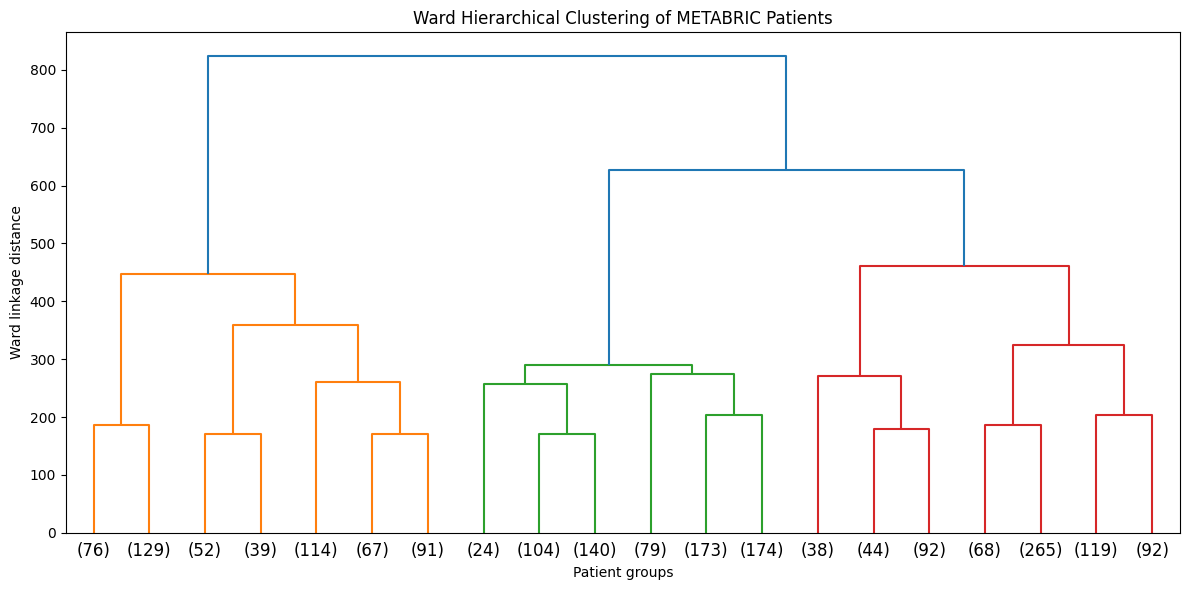

In [12]:
#Dendrogram

plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=20,
    show_leaf_counts=True
)

plt.title("Ward Hierarchical Clustering of METABRIC Patients")
plt.xlabel("Patient groups")
plt.ylabel("Ward linkage distance")

plt.tight_layout()
plt.show()


In [13]:
#Comparing to PAM50 subtypes
# Five main PAM50 subtypes
main_subtypes = ["LumA", "LumB", "Her2", "Basal", "Normal"]

# Create comparison dataframe for all clustered samples
comparison_df = pd.DataFrame({
    "PAM50": pam50_labels,
    "Ward_Cluster": ward_clusters
}, index=X_2000_imputed.index)

# Keep only the five main PAM50 subtypes for comparison
comparison_df = comparison_df[
    comparison_df["PAM50"].isin(main_subtypes)
].copy()

# Count patients in each cluster/subtype combination
comparison_table = pd.crosstab(
    comparison_df["Ward_Cluster"],
    comparison_df["PAM50"]
)

print("Patients included in comparison:", len(comparison_df))
print("\nPAM50 subtype distribution:")
print(comparison_df["PAM50"].value_counts())

print("\nWard clusters vs PAM50:")
print(comparison_table)

Patients included in comparison: 1756

PAM50 subtype distribution:
PAM50
LumA      700
LumB      475
Her2      224
Basal     209
Normal    148
Name: count, dtype: int64

Ward clusters vs PAM50:
PAM50         Basal  Her2  LumA  LumB  Normal
Ward_Cluster                                 
1               148     0     0     1       4
2                37   125    23    22      27
3                 6    26   409   121      92
4                14    39    74    34      11
5                 4    34   194   297      14


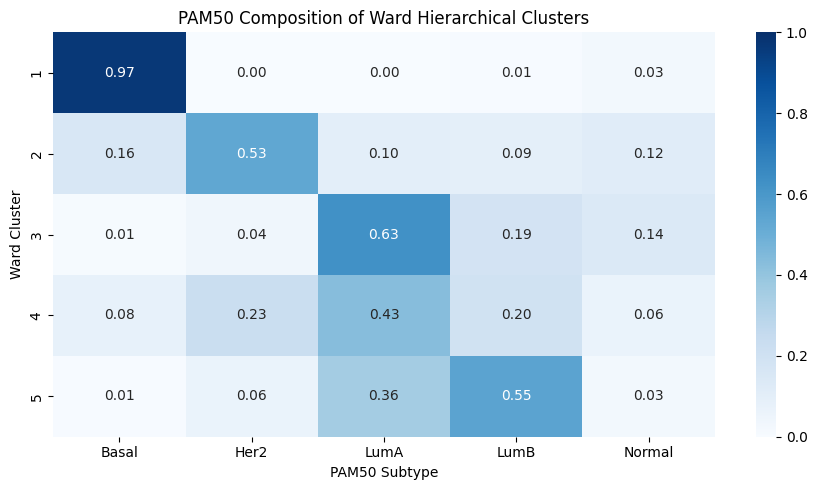

In [14]:
#Heatmap

# Convert counts into proportions within each cluster
cluster_proportions = comparison_table.div(
    comparison_table.sum(axis=1),
    axis=0
)

plt.figure(figsize=(9, 5))

sns.heatmap(
    cluster_proportions,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.title("PAM50 Composition of Ward Hierarchical Clusters")
plt.xlabel("PAM50 Subtype")
plt.ylabel("Ward Cluster")

plt.tight_layout()
plt.show()


In [15]:
#Saving clusters

comparison_df.to_csv(
    "ward_cluster_assignments.csv",
    index_label="SAMPLE_ID"
)

comparison_table.to_csv(
    "ward_pam50_counts.csv"
)

cluster_proportions.to_csv(
    "ward_pam50_proportions.csv"
)

labels_by_k = pd.DataFrame(
    {f"ward_k{k}": v for k, v in ward_by_k.items()},
    index=X_2000_imputed.index,
)
labels_by_k["PAM50"] = pam50_labels
labels_by_k.to_csv("ward_labels_k2_to_k10.csv", index_label="Sample_ID")

pd.Series(top_2000_genes, name="Entrez_Gene_Id").to_csv(
    "top2000_genes_by_MAD.csv", index=False
)